# Tutorial 3 — Camadas ao redor de uma geometria em L

## 1. Importações

In [1]:
from pathlib import Path
import sys

# Importar o pacote local
project_root = Path.cwd()
if project_root.name == "tutorials":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import numpy as np

from meshlab.core import Mesh, Curve, Contour, Front
from meshlab.operations import (
    insert_contour, initialize_front, compute_normals, advance_front,
    compute_angles, smooth_normals, find_short_edges, collapse_edges,
)
from meshlab.utils import plot_mesh

## 2. Parâmetros

In [2]:
num_layers = 3
height = 0.05
growth_rate = 1.10
points_per_edge = 5
smooth_steps = 5
relaxation = 1.0

## 3. Geometria em L

In [3]:
# Vértices em sentido anti-horário
vertices = np.array([
    [ 0.0,  0.0],
    [ 0.0,  1.0],
    [-0.5,  1.0],
    [-0.5, -1.0],
    [ 1.0, -1.0],
    [ 1.0,  0.0],
])

points = np.vstack([
    np.linspace(start, end, points_per_edge, endpoint=False)
    for start, end in zip(vertices, np.roll(vertices, -1, axis=0))
])
points = np.vstack((points, points[0]))
surface = Contour("l_body", [Curve("wall", points)])

## 4. Normais centrais, sem correção de altura

In [4]:
mesh = Mesh(dim=2)
insert_contour(mesh, surface)
front = Front("l_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, front, curves=["wall"])

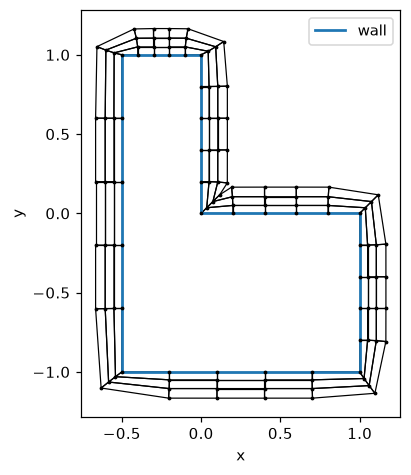

In [5]:
h = height
for _ in range(num_layers):
    normals = compute_normals(mesh, front, method="central")
    advance_front(mesh, front, normals, h)
    h *= growth_rate

plot_mesh(mesh);

## 5. Bissetoras com correção de altura

In [6]:
mesh = Mesh(dim=2)
insert_contour(mesh, surface)
front = Front("l_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, front, curves=["wall"])

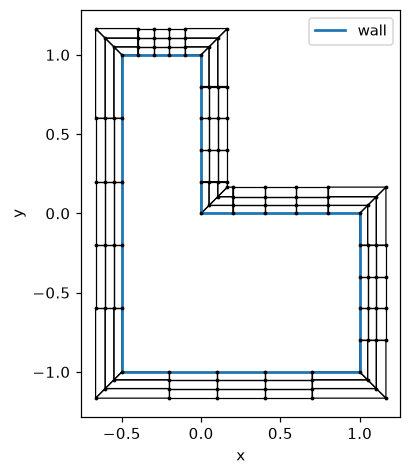

In [7]:
h = height
for _ in range(num_layers):
    normals = compute_normals(mesh, front, method="bisector")
    angles = compute_angles(mesh, front)
    heights = h / np.sin(angles / 2)
    advance_front(mesh, front, normals, heights)
    h *= growth_rate

plot_mesh(mesh);

## 6. Bissetoras suavizadas com correção de altura

In [8]:
mesh = Mesh(dim=2)
insert_contour(mesh, surface)
front = Front("l_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, front, curves=["wall"])

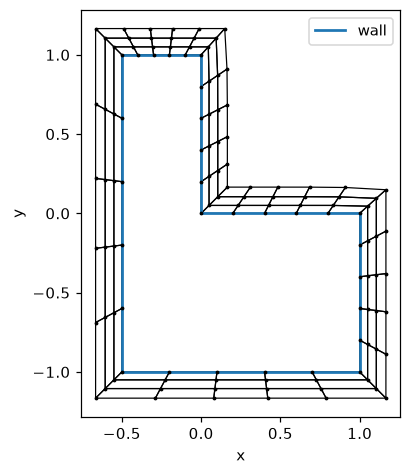

In [9]:
h = height
for _ in range(num_layers):
    normals = compute_normals(mesh, front, method="bisector")

    rotation = np.zeros(len(normals), dtype=mesh.float_dtype)
    for _ in range(smooth_steps):
        normals, step_rotation = smooth_normals(mesh, front, normals, relaxation)
        rotation += step_rotation

    angles = compute_angles(mesh, front)
    # Correção empírica usada no tutorial original
    heights = h / np.sin(angles / 2 + np.abs(rotation))
    advance_front(mesh, front, normals, heights)
    h *= growth_rate

plot_mesh(mesh);

## 7. Mais camadas com colapso de arestas curtas

In [ ]:
num_layers = 10
height = 0.04
min_edge_ratio = 1.5

mesh = Mesh(dim=2)
insert_contour(mesh, surface)
front = Front("l_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, front, curves=["wall"])

In [ ]:
h = height
total_collapsed = 0
for layer in range(num_layers):
    normals = compute_normals(mesh, front, method="bisector")
    angles = compute_angles(mesh, front)
    heights = h / np.sin(angles / 2)
    advance_front(mesh, front, normals, heights)

    edges = find_short_edges(mesh, front, min_edge_ratio * h)
    previous_count = len(front.entities.edge)
    # Atualizar mesh, front e os índices das fronteiras no próprio objeto
    index_map = collapse_edges(mesh, front, edges)

    collapsed = previous_count - len(front.entities.edge)
    total_collapsed += collapsed
    if collapsed:
        print(f"Camada {layer + 1}: {collapsed} arestas colapsadas.")
    h *= growth_rate

print(f"Total: {total_collapsed} arestas colapsadas.")
plot_mesh(mesh);